# 21 - League-strength Elo: one rating scale across leagues

Every league is rated on its own today, each averaging 1500, so a 1600 in the
Eredivisie and a 1600 in the Premier League look the same. Phase 4 puts every
club on **one shared scale** by giving each league a baseline
`B_L = 1500 + O_L` (docs/multi-league-plan.md §4A), and tests that scale on the
only matches where it matters: European ties between clubs from different
leagues (CL + EL + ECL, P4-01).

**What's chosen here (P4-03):**

- **Offsets** - option **A**, the UEFA log map `O_L = s · ln(C_L / C_ENG)` with
  point-in-time 5-year country coefficients (P4-02), `s` fitted; option **C**,
  offsets fitted from European results with an L2 pull towards A, as the
  challenger. Option B (ClubElo) is a sanity check only, if its API is up.
- **Update variant** (D11, all four):
  - **E1** static offsets - European results update nothing on the domestic side;
  - **E2b** league-level - they nudge the offsets, `O_L ± k_L (S − E)`;
  - **E2a** team-level - they move the two clubs' ratings by `K_CL (S − E)`;
  - **E2a+E2b** - both.
- **Clubs outside the 7 modelled leagues** (about half of all European
  appearances): start at `B_country + E_entrant`, carried between seasons as
  `B + ρ (R − B)`, updated by every European match with `K_CL`.
- **Warm-up** (D3): W0 none; W1 results-only 17-18 and 18-19; W2 18-19 to 20-21
  including the COVID seasons with no home advantage behind closed doors.

**Protocol** (§5): the Elo expected score `E` is scored against the 90-minute
result `S` (1 / ½ / 0) with log loss `−[S ln E + (1 − S) ln(1 − E)]`, on
**cross-league** European matches (`HomeLeague ≠ AwayLeague`). Every
parameter is chosen on **22-23/23-24** and reported on **24-25/25-26**. 21-22
is history only: every rating starts cold there. Paired bootstrap, 5,000
resamples, seed 42. *Better* = 95% CI upper < 0; *non-inferior* = upper <
+0.002.

**Gates** (§2 Phase 4):

1. **Domestic invariance** - under E1 and E2b, every domestic `EloDiff` equals
   the pipeline's (max |diff| < 1e-9).
2. **Offsets beat no offsets** - European cross-league log loss better than the
   `s = 0` control.
3. **E2a, E2a+E2b** change domestic `EloDiff`, so they must be non-inferior to
   E2b on domestic log loss (the shipped LR), overall and on matches involving
   clubs in Europe that season. Among the variants that pass, the best European
   log loss ships.
4. **Warm-up** is adopted only if it's *better* than W0 on both European and
   domestic log loss, 22-23 to 25-26.

In [1]:
import itertools
import math
import os
import sys
import tempfile
import urllib.request
import warnings
from collections import defaultdict
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)  # the pipeline reads data/ relative to the repo root
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

import competitions
import european
from load_data import build_dataset
from features import build_goals_per_game_feature, build_xgd_last5_feature
from elo import build_elo_feature, HOME_ADVANTAGE, UPDATE_SIZE, LEAGUE_BASE_ELO
from model import league_columns, walk_forward_models
from team_names import load_alias_map
from evaluate import per_match_log_loss, paired_bootstrap, seasons_better, better, non_inferior

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

DIVS = competitions.enabled()
LEAGUE_COUNTRY = {div: competitions.get(div)["country"] for div in DIVS}
OTHER_LEAGUES = [div for div in DIVS if div != "E0"]  # O_E0 = 0 anchors the scale

TUNE, REPORT = ["22-23", "23-24"], ["24-25", "25-26"]
TEST = TUNE + REPORT
LABELS = ["A", "D", "H"]
SCORE = {"H": 1.0, "D": 0.5, "A": 0.0}

GRID = {
    "s": [0, 100, 150, 200, 250, 300],
    "ha": [80, 100, 130],          # HA_CL
    "k_cl": [10, 20, 35],          # K_CL
    "k_l": [1, 2, 4],              # offset learning rate (E2b)
    "entrant": [0, 50, 100, 150],  # E_entrant
    "rho": [0.5, 0.75],
}
VARIANTS = ["E1", "E2b", "E2a", "E2a+E2b"]
assert all(competitions.get(d)["promoted_elo"] is None for d in DIVS), "engine assumes no promoted resets"
DIVS

['E0', 'SP1', 'D1', 'I1', 'F1', 'P1', 'N1']

## Data

**Domestic** - the pipeline's dataset for the 7 enabled leagues, built from
cache (no network), with the pipeline's own features. Its `EloDiff` is the
reference for gate 1 and the domestic model is the shipped one
(`walk_forward_models`: E0 on its own model, the rest pooled).

In [2]:
with tempfile.TemporaryDirectory() as tmp:
    matches = build_dataset(DIVS, output_path=Path(tmp) / "all_matches.csv", refresh_current=False)

matches = matches.sort_values(["MatchDateTime", "HomeTeam", "AwayTeam"]).reset_index(drop=True)
build_elo_feature(matches)
build_goals_per_game_feature(matches)
build_xgd_last5_feature(matches)
matches = league_columns(matches)
PIPELINE_ELODIFF = matches["EloDiff"].to_numpy().copy()

matches.groupby(["Div", "Season"]).size().unstack("Season")

Built 12609 matches (100.0% xG coverage, 1 from football-data/Understat backup)


Saved C:\Users\harry\AppData\Local\Temp\tmpw48s4z01\all_matches.csv


Season,21-22,22-23,23-24,24-25,25-26,26-27
Div,,,,,,
D1,306,306,306,306,306,72
E0,380,380,380,380,380,90
F1,380,380,306,306,306,81
I1,380,380,380,380,380,100
N1,306,306,306,306,306,99
P1,306,306,306,306,306,90
SP1,380,380,380,380,380,109


**European** - P4-01's caches through `european.load_european`, 21-22 to
25-26 (26-27 is unfinished). `FTR` is the 90-minute result. A club's
`HomeLeague` is its Div that season, or `X:<country>` outside the 7 leagues.

In [3]:
eu = european.load_european(domestic=matches)
eu = eu[(eu["Season"] >= "21-22") & (eu["Season"] <= "25-26")].reset_index(drop=True)

eu["Cross"] = eu["HomeLeague"] != eu["AwayLeague"]
eu["Unmodelled"] = eu["HomeLeague"].str.startswith("X:") | eu["AwayLeague"].str.startswith("X:")
eu["BothModelled"] = ~eu["HomeLeague"].str.startswith("X:") & ~eu["AwayLeague"].str.startswith("X:")

(
    eu.groupby(["Season", "Div"])
    .agg(matches=("FTR", "size"), cross=("Cross", "sum"),
         modelled_v_modelled=("BothModelled", "sum"), with_unmodelled=("Unmodelled", "sum"))
    .unstack("Div")
)

matches           cross           modelled_v_modelled         with_unmodelled          
Div         CL  ECL   EL    CL  ECL   EL                  CL ECL  EL              CL  ECL   EL
Season                                                                                        
21-22      125  140  139   125  140  139                  73  18  36              52  122  103
22-23      125  141  141   121  141  141                  73   9  41              52  132  100
23-24      125  141  141   125  141  139                  81   6  43              44  135   98
24-25      189  153  189   183  151  188                 113   7  40              76  146  149
25-26      189  153  189   185  153  185                 105  10  52              84  143  137

In [4]:
cross = eu[eu["Cross"]]
print(f"{len(eu)} European matches, {len(cross)} cross-league; "
      f"tune {cross['Season'].isin(TUNE).sum()}, report {cross['Season'].isin(REPORT).sum()}")
print("90-minute results, cross-league:", cross["FTR"].value_counts(normalize=True).round(3).to_dict())

2280 European matches, 2257 cross-league; tune 808, report 1045
90-minute results, cross-league: {'H': 0.482, 'A': 0.309, 'D': 0.209}


**UEFA country coefficients** (P4-02): season `YY-YY+1` uses the ranking at
kick-off. What option A's map gives at `s = 200` (illustration only - the fit
sets `s`):

In [5]:
coef = pd.read_csv("data/reference/uefa_country_coefficients.csv")
COEF = {(row.country, row.season): row.coefficient for row in coef.itertuples()}


def uefa_offset(country, season, s):
    # O = s * ln(C_country / C_ENG), point in time
    return s * math.log(COEF[(country, season)] / COEF[("ENG", season)])


pd.DataFrame({
    season: {div: round(uefa_offset(LEAGUE_COUNTRY[div], season, 200)) for div in DIVS}
    for season in ["21-22", "22-23", "23-24", "24-25", "25-26"]
})

,21-22,22-23,23-24,24-25,25-26
E0,0,0,0,0,0
SP1,-5,-21,-33,-31,-40
D1,-63,-70,-57,-37,-58
I1,-58,-65,-58,-29,-34
F1,-117,-115,-117,-89,-91
P1,-146,-138,-133,-123,-123
N1,-188,-154,-121,-106,-108


**Warm-up results** (W1/W2): football-data.co.uk 17-18 to 20-21, results
only, kept in `data/raw/warmup/` so the pipeline never sees them as seasons.
Names go through `team_names.csv`; a club that's gone from the leagues by
21-22 keeps its football-data name (it only matters as an opponent).

In [6]:
WARMUP_DIR = Path("data/raw/warmup")
alias = load_alias_map()


def read_results(path):
    for encoding in ("utf-8-sig", "latin-1"):
        try:
            return pd.read_csv(path, encoding=encoding,
                               usecols=lambda c: c in {"Date", "Time", "HomeTeam", "AwayTeam", "FTR"})
        except UnicodeDecodeError:
            continue


def load_warmup(seasons):
    from fetch_results import REQUEST_HEADERS, season_url
    frames = []
    for div in DIVS:
        for season in seasons:
            path = WARMUP_DIR / div / f"results_{season}.csv"
            if not path.exists():
                path.parent.mkdir(parents=True, exist_ok=True)
                request = urllib.request.Request(season_url(div, season), headers=REQUEST_HEADERS)
                with urllib.request.urlopen(request, timeout=30) as response:
                    path.write_bytes(response.read())
            frame = read_results(path).dropna(subset=["FTR"])
            frame["Div"], frame["Season"] = div, season
            frame["Day"] = pd.to_datetime(frame["Date"], dayfirst=True)
            frames.append(frame)
    warm = pd.concat(frames, ignore_index=True)
    warm["Time"] = warm["Time"].fillna("") if "Time" in warm else ""
    for side in ("HomeTeam", "AwayTeam"):
        warm[side] = warm[side].map(lambda name: alias.get(name, name))
    return warm.sort_values(["Day", "Time", "HomeTeam"]).reset_index(drop=True)


WARMUPS = {"W1": load_warmup(["17-18", "18-19"]), "W2": load_warmup(["18-19", "19-20", "20-21"])}
pd.DataFrame({name: frame.groupby("Season").size() for name, frame in WARMUPS.items()})

,W1,W2
Season,,
17-18,2438.0,NaN
18-19,2438.0,2438.0
19-20,NaN,2263.0
20-21,NaN,2438.0


## The rating engine

One chronological pass over domestic and European matches (a European match
on day *d* comes after every domestic match up to *d*).

- **Domestic** is today's Elo exactly: rated per league, `K = 35`, `HA = 130`.
  Each club's domestic rating `r` lives in its league.
- **Re-centring** (§4A.1): a league's shared-scale baseline is
  `δ_{L,s} = mean(r − t) − 1500` over the clubs in L that season, where `t` is a
  club's running total of European transfers (E2a; 0 otherwise). Domestic
  updates are zero-sum and no league resets promoted clubs, so this is one
  constant per league and season: a uniform shift that leaves `EloDiff` alone.
  Promotion drift is removed; points won in Europe under E2a are not.
- **Shared scale**: a modelled club is `R = r − δ_{L,s} + O_L`, with
  `O_L = A_L(s) + D_L` (`D_L` learned under E2b, anchored at `D_E0 = 0`).
  An unmodelled club holds `R` directly.
- **European match**: `E = 1 / (1 + 10^(−(R_h + HA_CL·(1 − Neutral) − R_a) / 400))`,
  then unmodelled clubs move by `K_CL (S − E)`; under E2a modelled clubs do
  too; under E2b, a match between two different modelled leagues moves their
  offsets by `± k_L (S − E)` (only the non-E0 side when E0 is involved).

In [7]:
dom_days = matches["MatchDateTime"].dt.normalize()
DOMESTIC = [
    (0, i, div, season, home, away, SCORE[ftr], HOME_ADVANTAGE)
    for i, (div, season, home, away, ftr) in enumerate(
        zip(matches["Div"], matches["Season"], matches["HomeTeam"], matches["AwayTeam"], matches["FTR"]))
]
EUROPEAN = [
    (1, i, season, home, away, hl, al, SCORE[ftr], neutral)
    for i, (season, home, away, hl, al, ftr, neutral) in enumerate(
        zip(eu["Season"], eu["HomeTeam"], eu["AwayTeam"], eu["HomeLeague"], eu["AwayLeague"], eu["FTR"], eu["Neutral"]))
]
PARTICIPANTS = {
    key: sorted(set(group["HomeTeam"]) | set(group["AwayTeam"]))
    for key, group in matches.groupby(["Div", "Season"])
}


def make_events(warmup=None, closed_doors_ha=False):
    timeline = sorted(
        [(day, 0, i) for i, day in enumerate(dom_days)]
        + [(day, 1, i) for i, day in enumerate(eu["Date"])]
    )
    events = [DOMESTIC[i] if kind == 0 else EUROPEAN[i] for _, kind, i in timeline]
    if warmup is None:
        return events
    # Behind closed doors (W2): no home advantage from the March 2020 shutdown on
    closed = warmup["Day"] >= "2020-03-14"
    prefix = [
        (0, -1, div, season, home, away, SCORE[ftr], 0 if (closed_doors_ha and shut) else HOME_ADVANTAGE)
        for div, season, home, away, ftr, shut in zip(
            warmup["Div"], warmup["Season"], warmup["HomeTeam"], warmup["AwayTeam"], warmup["FTR"], closed)
    ]
    return prefix + events


EVENTS = {
    "W0": make_events(),
    "W1": make_events(WARMUPS["W1"]),
    "W2": make_events(WARMUPS["W2"], closed_doors_ha=True),
}


def run(p, variant="E1", warmup="W0", static_offsets=None, final_season=None):
    # One pass. p: s, ha, k_cl, k_l, entrant, rho. static_offsets {Div: O}
    # replaces A + D for the modelled leagues (option C).
    team_level = variant in ("E2a", "E2a+E2b")
    league_level = variant in ("E2b", "E2a+E2b")
    s, ha, k_cl, k_l, entrant, rho = (p[k] for k in ("s", "ha", "k_cl", "k_l", "entrant", "rho"))

    r = {}                      # (Div, club) -> domestic rating
    t = defaultdict(float)      # (Div, club) -> European transfers so far (E2a)
    learned = defaultdict(float)  # Div -> D_L (E2b)
    delta, a_cache, unmodelled = {}, {}, {}

    def a_offset(country, season):
        key = (country, season)
        if key not in a_cache:
            a_cache[key] = uefa_offset(country, season, s)
        return a_cache[key]

    def league_offset(div, season):
        if static_offsets is not None:
            return static_offsets[div]
        return a_offset(LEAGUE_COUNTRY[div], season) + learned[div]

    def recentre(div, season):
        key = (div, season)
        if key not in delta:
            delta[key] = np.mean([
                r.get((div, club), LEAGUE_BASE_ELO) - t[(div, club)] for club in PARTICIPANTS[key]
            ]) - LEAGUE_BASE_ELO
        return delta[key]

    def outsider(club, country, season):
        # [rating, season, that season's baseline]
        state = unmodelled.get(club)
        base = LEAGUE_BASE_ELO + a_offset(country, season)
        if state is None:
            state = unmodelled[club] = [base + entrant, season, base]
        elif state[1] != season:
            state[0] = base + rho * (state[0] - state[2])
            state[1], state[2] = season, base
        return state

    domestic_diff = np.empty(len(DOMESTIC))
    expected = np.empty(len(EUROPEAN))

    for event in EVENTS[warmup]:

        if event[0] == 0:
            _, i, div, season, home, away, score, home_adv = event
            rh, ra = r.get((div, home), LEAGUE_BASE_ELO), r.get((div, away), LEAGUE_BASE_ELO)
            if i >= 0:
                domestic_diff[i] = rh - ra
            e = 1 / (1 + 10 ** (-(rh + home_adv - ra) / 400))
            r[(div, home)] = rh + UPDATE_SIZE * (score - e)
            r[(div, away)] = ra - UPDATE_SIZE * (score - e)
            continue

        _, i, season, home, away, hl, al, score, neutral = event
        home_in, away_in = not hl.startswith("X:"), not al.startswith("X:")

        if home_in:
            rh = r.get((hl, home), LEAGUE_BASE_ELO) - recentre(hl, season) + league_offset(hl, season)
        else:
            home_state = outsider(home, hl[2:], season)
            rh = home_state[0]
        if away_in:
            ra = r.get((al, away), LEAGUE_BASE_ELO) - recentre(al, season) + league_offset(al, season)
        else:
            away_state = outsider(away, al[2:], season)
            ra = away_state[0]

        e = 1 / (1 + 10 ** (-(rh + ha * (1 - neutral) - ra) / 400))
        expected[i] = e
        change = score - e

        if not home_in:
            home_state[0] += k_cl * change
        elif team_level:
            r[(hl, home)] = r.get((hl, home), LEAGUE_BASE_ELO) + k_cl * change
            t[(hl, home)] += k_cl * change
        if not away_in:
            away_state[0] -= k_cl * change
        elif team_level:
            r[(al, away)] = r.get((al, away), LEAGUE_BASE_ELO) - k_cl * change
            t[(al, away)] -= k_cl * change

        if league_level and home_in and away_in and hl != al:
            if hl != "E0":
                learned[hl] += k_l * change
            if al != "E0":
                learned[al] -= k_l * change

    out = {"dom": domestic_diff, "E": expected, "learned": dict(learned)}

    if final_season is not None:
        rows = [
            {"Club": club, "League": div,
             "Rating": r[(div, club)] - recentre(div, final_season) + league_offset(div, final_season)}
            for div in DIVS for club in PARTICIPANTS[(div, final_season)]
        ]
        rows += [
            {"Club": club, "League": f"X:{eu.loc[(eu['HomeTeam'] == club), 'HomeLeague'].iloc[-1][2:]}"
             if (eu["HomeTeam"] == club).any() else "X:?", "Rating": state[0]}
            for club, state in unmodelled.items() if state[1] == final_season
        ]
        out["ratings"] = pd.DataFrame(rows).sort_values("Rating", ascending=False).reset_index(drop=True)

    return out


S_EU = eu["FTR"].map(SCORE).to_numpy()
CROSS = eu["Cross"].to_numpy()


def score_loss(e):
    # per-match log loss of the expected score against the 90-minute result
    return -(S_EU * np.log(e) + (1 - S_EU) * np.log(1 - e))


def eu_mask(seasons, frame_mask=None):
    mask = CROSS & eu["Season"].isin(seasons).to_numpy()
    return mask if frame_mask is None else mask & frame_mask


%time _ = run(dict(s=200, ha=100, k_cl=20, k_l=2, entrant=100, rho=0.5), "E2a+E2b")

CPU times: total: 31.2 ms
Wall time: 34.4 ms


## Gate 1 - domestic invariance (E1, E2b)

Across a spread of parameters, including the extremes of the grid, every
domestic `EloDiff` from the engine must equal the pipeline's.

In [8]:
checks = []
for variant in ["E1", "E2b"]:
    for p in [dict(s=0, ha=80, k_cl=10, k_l=1, entrant=0, rho=0.5),
              dict(s=300, ha=130, k_cl=35, k_l=4, entrant=150, rho=0.75),
              dict(s=200, ha=100, k_cl=20, k_l=2, entrant=100, rho=0.5)]:
        diff = np.abs(run(p, variant)["dom"] - PIPELINE_ELODIFF).max()
        checks.append({"variant": variant, **p, "max |EloDiff diff|": diff, "pass": diff < 1e-9})
gate1 = pd.DataFrame(checks)
assert gate1["pass"].all()
print(f"Gate 1 (max |diff| < 1e-9 for E1 and E2b): PASS - worst {gate1['max |EloDiff diff|'].max():.1e}")
gate1

Gate 1 (max |diff| < 1e-9 for E1 and E2b): PASS - worst 4.5e-13


,variant,s,ha,k_cl,k_l,entrant,rho,max |EloDiff diff|,pass
0,E1,0,80,10,1,0,0.50,4.547474e-13,True
1,E1,300,130,35,4,150,0.75,4.547474e-13,True
2,E1,200,100,20,2,100,0.50,4.547474e-13,True
3,E2b,0,80,10,1,0,0.50,4.547474e-13,True
4,E2b,300,130,35,4,150,0.75,4.547474e-13,True
5,E2b,200,100,20,2,100,0.50,4.547474e-13,True


## Grid search (tune on 22-23/23-24)

Every combination of `s × HA_CL × K_CL × E_entrant × ρ` (× `k_L` for the E2b
variants), scored on tune-season cross-league matches.

In [9]:
def configs(variant):
    keys = ["s", "ha", "k_cl", "entrant", "rho"] + (["k_l"] if variant in ("E2b", "E2a+E2b") else [])
    for values in itertools.product(*(GRID[k] for k in keys)):
        yield {"k_l": 0, **dict(zip(keys, values))}


rows = []
for variant in VARIANTS:
    for p in configs(variant):
        loss = score_loss(run(p, variant)["E"])
        rows.append({"variant": variant, **p,
                     "tune": loss[eu_mask(TUNE)].mean(), "report": loss[eu_mask(REPORT)].mean()})
grid = pd.DataFrame(rows)
print(f"{len(grid)} runs")

PARAMS = ["s", "ha", "k_cl", "k_l", "entrant", "rho"]


def best(frame):
    row = frame.loc[frame["tune"].idxmin()]
    return {k: (row[k].item() if hasattr(row[k], "item") else row[k]) for k in PARAMS}


CHOSEN = {variant: best(grid[grid["variant"] == variant]) for variant in VARIANTS}
CHOSEN["Control (s=0)"] = best(grid[(grid["variant"] == "E1") & (grid["s"] == 0)])
CONTROL_VARIANT = {"Control (s=0)": "E1"}

pd.DataFrame([
    {"candidate": name, **p,
     **grid.loc[(grid["variant"] == CONTROL_VARIANT.get(name, name))
                & np.logical_and.reduce([grid[k] == v for k, v in p.items()]), ["tune", "report"]].iloc[0].to_dict()}
    for name, p in CHOSEN.items()
]).round(4)

3456 runs


,candidate,s,ha,k_cl,k_l,entrant,rho,tune,report
0,E1,150,80,35,0,0,0.75,0.6107,0.6340
1,E2b,150,80,35,4,0,0.75,0.6079,0.6274
2,E2a,150,80,35,0,0,0.50,0.6062,0.6229
3,E2a+E2b,150,80,35,4,0,0.50,0.6047,0.6211
4,Control (s=0),0,80,35,0,0,0.50,0.6455,0.6638


How the best tune-season loss moves with `s` (E1, everything else at its best
for that `s`) - the shape of option A's one parameter:

In [10]:
(
    grid[grid["variant"].isin(["E1", "E2b"])]
    .groupby(["variant", "s"])["tune"].min()
    .unstack("variant").round(4)
)

variant,E1,E2b
s,,
0,0.6455,0.6397
100,0.6134,0.6098
150,0.6107,0.6079
200,0.6122,0.6099
250,0.6159,0.6139
300,0.6235,0.6217


## Option C - offsets fitted from European results (challenger)

For each test season, fit the six non-E0 offsets and `HA_CL` by maximum
likelihood on every earlier season's cross-league European matches, with an
L2 penalty `λ Σ (O_L − A_L)²` pulling towards option A at E1's chosen `s`.
Offsets are static within a season (E1 dynamics); unmodelled countries keep
option A's baseline. `λ` is chosen on 22-23/23-24.

In [11]:
A_STAR = CHOSEN["E1"]
LAMBDAS = [0.0003, 0.003, 0.03]
SEASONS_ALL = ["21-22", "22-23", "23-24", "24-25", "25-26"]


def fit_c(test_season, lam):
    prior = {div: uefa_offset(LEAGUE_COUNTRY[div], test_season, A_STAR["s"]) for div in OTHER_LEAGUES}
    train = eu_mask([s for s in SEASONS_ALL if s < test_season])

    def objective(x):
        offsets = {"E0": 0.0, **dict(zip(OTHER_LEAGUES, x[:-1]))}
        e = run({**A_STAR, "ha": x[-1]}, "E1", static_offsets=offsets)["E"]
        penalty = lam * sum((offsets[d] - prior[d]) ** 2 for d in OTHER_LEAGUES)
        return score_loss(e)[train].sum() + penalty

    x0 = np.array([prior[d] for d in OTHER_LEAGUES] + [A_STAR["ha"]], dtype=float)
    fit = minimize(objective, x0, method="L-BFGS-B", options={"eps": 0.5, "maxiter": 200})
    offsets = {"E0": 0.0, **dict(zip(OTHER_LEAGUES, fit.x[:-1]))}
    return offsets, fit.x[-1]


c_runs, c_offsets = {}, {}
for lam in LAMBDAS:
    e_c = np.full(len(eu), np.nan)
    for season in TEST:
        offsets, ha = fit_c(season, lam)
        c_offsets[(lam, season)] = {**{d: round(o) for d, o in offsets.items()}, "HA_CL": round(ha)}
        e = run({**A_STAR, "ha": ha}, "E1", static_offsets=offsets)["E"]
        in_season = (eu["Season"] == season).to_numpy()
        e_c[in_season] = e[in_season]
    c_runs[lam] = e_c

c_table = pd.DataFrame([
    {"lambda": lam, "tune": score_loss(e)[eu_mask(TUNE)].mean(), "report": score_loss(e)[eu_mask(REPORT)].mean()}
    for lam, e in c_runs.items()
])
LAMBDA = c_table.loc[c_table["tune"].idxmin(), "lambda"]
print(f"Chosen lambda: {LAMBDA}; E1 (option A) tune {grid.loc[(grid['variant'] == 'E1'), 'tune'].min():.4f}")
c_table.round(4)

Chosen lambda: 0.0003; E1 (option A) tune 0.6107


,lambda,tune,report
0,0.0003,0.6099,0.6233
1,0.0030,0.6107,0.6316
2,0.0300,0.6111,0.6341


In [12]:
# Option C's fitted offsets (and HA_CL) per test season, next to option A's
pd.DataFrame({
    **{f"C {season}": c_offsets[(LAMBDA, season)] for season in TEST},
    **{f"A {season}": {**{d: round(uefa_offset(LEAGUE_COUNTRY[d], season, A_STAR["s"])) for d in DIVS},
                       "HA_CL": A_STAR["ha"]} for season in TEST},
})

,C 22-23,C 23-24,C 24-25,C 25-26,A 22-23,A 23-24,A 24-25,A 25-26
E0,0,0,0,0,0,0,0,0
SP1,-38,-55,-42,-54,-16,-25,-23,-30
D1,-55,-44,-31,-46,-52,-43,-28,-43
I1,-61,-57,-34,-40,-49,-44,-22,-25
F1,-50,-76,-54,-62,-86,-87,-67,-68
P1,-122,-135,-156,-176,-104,-100,-92,-92
N1,-94,-105,-129,-150,-116,-91,-80,-81
HA_CL,57,64,68,73,80,80,80,80


## Gate 2 - offsets vs no offsets (report seasons)

Each candidate at its tune-season parameters against the `s = 0` control (E1
with no offsets, its other parameters tuned the same way), on 24-25/25-26
cross-league matches.

In [13]:
E_RUNS = {name: run(p, CONTROL_VARIANT.get(name, name))["E"] for name, p in CHOSEN.items()}
E_RUNS["C (E1)"] = c_runs[LAMBDA]
SEASON_COL = eu["Season"].to_numpy()


def eu_compare(candidate, reference, seasons=REPORT, subset=None):
    mask = eu_mask(seasons, subset)
    diff = score_loss(E_RUNS[candidate])[mask] - score_loss(E_RUNS[reference])[mask]
    result = paired_bootstrap(diff)
    by_season = [
        score_loss(E_RUNS[candidate])[mask & (SEASON_COL == s)].mean()
        < score_loss(E_RUNS[reference])[mask & (SEASON_COL == s)].mean()
        for s in seasons
    ]
    return {"matches": int(mask.sum()), "logLoss": score_loss(E_RUNS[candidate])[mask].mean(),
            "mean": result["mean"], "ciLow": result["ci"][0], "ciHigh": result["ci"][1],
            "pBetter": result["p_better"], "seasonsBetter": f"{sum(by_season)}/{len(seasons)}",
            "better": better(result["ci"])}


CANDIDATES = ["E1", "E2b", "E2a", "E2a+E2b", "C (E1)"]
gate2 = pd.DataFrame([{"candidate": c, **eu_compare(c, "Control (s=0)")} for c in CANDIDATES])
print(f"Control (s=0) report log loss: {score_loss(E_RUNS['Control (s=0)'])[eu_mask(REPORT)].mean():.4f}")
gate2.round(4)

Control (s=0) report log loss: 0.6638


,candidate,matches,logLoss,mean,ciLow,ciHigh,pBetter,seasonsBetter,better
0,E1,1045,0.6340,-0.0298,-0.0435,-0.0161,1.0,2/2,True
1,E2b,1045,0.6274,-0.0363,-0.0506,-0.0216,1.0,2/2,True
2,E2a,1045,0.6229,-0.0408,-0.0562,-0.0253,1.0,2/2,True
3,E2a+E2b,1045,0.6211,-0.0427,-0.0587,-0.0263,1.0,2/2,True
4,C (E1),1045,0.6233,-0.0405,-0.0547,-0.0259,1.0,2/2,True


Where the gain comes from - the same comparison on modelled-vs-modelled
matches (two of the 7 leagues) and on matches with a club from outside them:

In [14]:
both = eu["BothModelled"].to_numpy()
pd.DataFrame(
    [{"candidate": c, "subset": "modelled v modelled", **eu_compare(c, "Control (s=0)", subset=both)} for c in CANDIDATES]
    + [{"candidate": c, "subset": "with an unmodelled club", **eu_compare(c, "Control (s=0)", subset=~both)} for c in CANDIDATES]
).round(4)

,candidate,subset,matches,logLoss,mean,ciLow,ciHigh,pBetter,seasonsBetter,better
0,E1,modelled v modelled,312,0.6658,-0.0382,-0.0521,-0.0251,1.0000,2/2,True
1,E2b,modelled v modelled,312,0.6539,-0.0501,-0.0707,-0.0299,1.0000,2/2,True
2,E2a,modelled v modelled,312,0.6375,-0.0665,-0.0923,-0.0412,1.0000,2/2,True
3,E2a+E2b,modelled v modelled,312,0.6358,-0.0683,-0.0977,-0.0391,1.0000,2/2,True
4,C (E1),modelled v modelled,312,0.6454,-0.0586,-0.0812,-0.0369,1.0000,2/2,True
5,E1,with an unmodelled club,733,0.6204,-0.0262,-0.0449,-0.0069,0.9952,2/2,True
6,E2b,with an unmodelled club,733,0.6162,-0.0305,-0.0492,-0.0114,0.9990,2/2,True
7,E2a,with an unmodelled club,733,0.6167,-0.0299,-0.0493,-0.0104,0.9976,2/2,True
8,E2a+E2b,with an unmodelled club,733,0.6149,-0.0318,-0.0512,-0.0120,0.9988,2/2,True
9,C (E1),with an unmodelled club,733,0.6139,-0.0328,-0.0511,-0.0142,0.9994,2/2,True


And the variants against each other (E2b is the plan's recommendation):

In [15]:
pd.DataFrame([
    {"candidate": c, "reference": ref, **eu_compare(c, ref)}
    for c, ref in [("E2b", "E1"), ("E2a", "E2b"), ("E2a+E2b", "E2b"), ("E2a+E2b", "E2a"), ("C (E1)", "E1")]
]).round(4)

,candidate,reference,matches,logLoss,mean,ciLow,ciHigh,pBetter,seasonsBetter,better
0,E2b,E1,1045,0.6274,-0.0065,-0.0101,-0.0028,0.9998,2/2,True
1,E2a,E2b,1045,0.6229,-0.0045,-0.0092,0.0002,0.9698,2/2,False
2,E2a+E2b,E2b,1045,0.6211,-0.0063,-0.0113,-0.0013,0.9942,2/2,True
3,E2a+E2b,E2a,1045,0.6211,-0.0018,-0.0038,0.0003,0.9550,2/2,False
4,C (E1),E1,1045,0.6233,-0.0107,-0.0153,-0.0061,1.0000,2/2,True


## Gate 3 - E2a variants on domestic log loss

E2a and E2a+E2b move the ratings of clubs that play in Europe, so the
domestic `EloDiff` changes. The shipped model (`walk_forward_models`) is
re-run with each variant's `EloDiff`, everything else unchanged, and compared
with E2b, whose `EloDiff` is the pipeline's (gate 1). Domestic parameters were
never tuned here, so all four test seasons 22-23 to 25-26 count. Subset:
domestic matches involving a club that played in Europe that season.

In [16]:
def domestic_proba(elo_diff):
    frame = matches.copy()
    frame["EloDiff"] = elo_diff
    return walk_forward_models(frame, TEST)[LABELS]


DOM_PROBA = {"E2b": domestic_proba(PIPELINE_ELODIFF)}
for variant in ["E2a", "E2a+E2b"]:
    DOM_PROBA[variant] = domestic_proba(run(CHOSEN[variant], variant)["dom"])

test_rows = matches[matches["Season"].isin(TEST)]
in_europe = set(zip(eu["Season"], eu["HomeTeam"])) | set(zip(eu["Season"], eu["AwayTeam"]))
europe_club = np.array([
    (season, home) in in_europe or (season, away) in in_europe
    for season, home, away in zip(test_rows["Season"], test_rows["HomeTeam"], test_rows["AwayTeam"])
])


def dom_compare(candidate, reference, mask):
    rows = test_rows[mask]
    y = rows["FTR"].to_numpy()
    cand = DOM_PROBA[candidate].loc[rows.index].to_numpy()
    ref = DOM_PROBA[reference].loc[rows.index].to_numpy()
    diff = per_match_log_loss(y, cand, LABELS) - per_match_log_loss(y, ref, LABELS)
    result = paired_bootstrap(diff)
    return {"matches": len(rows), "mean": result["mean"], "ciLow": result["ci"][0], "ciHigh": result["ci"][1],
            "pBetter": result["p_better"],
            "seasonsBetter": f"{seasons_better(y, cand, ref, rows['Season'], LABELS)}/{rows['Season'].nunique()}",
            "nonInferior": non_inferior(result["ci"])}


gate3 = pd.DataFrame([
    {"candidate": c, "matches in": subset_name, **dom_compare(c, "E2b", mask)}
    for c in ["E2a", "E2a+E2b"]
    for subset_name, mask in [("all domestic", np.ones(len(test_rows), bool)), ("clubs in Europe", europe_club)]
])
print(f"{europe_club.sum()} of {len(test_rows)} domestic test matches involve a club in Europe that season")
gate3.round(4)

5466 of 9530 domestic test matches involve a club in Europe that season


,candidate,matches in,matches,mean,ciLow,ciHigh,pBetter,seasonsBetter,nonInferior
0,E2a,all domestic,9530,-0.0000,-0.0009,0.0008,0.4994,2/4,True
1,E2a,clubs in Europe,5466,-0.0000,-0.0015,0.0015,0.5118,2/4,True
2,E2a+E2b,all domestic,9530,-0.0001,-0.0009,0.0008,0.5456,2/4,True
3,E2a+E2b,clubs in Europe,5466,-0.0001,-0.0015,0.0013,0.5586,2/4,True


## Choosing the variant

A candidate ships only if it passes every gate that applies to it: gate 2
(better than no offsets), and for the E2a variants gate 3 (non-inferior
domestically, overall and on the Europe-club subset). E1, E2b and C leave
the domestic ratings untouched (gate 1). Among those that pass, the lowest
report-season European log loss wins (tune-season loss shown alongside).

In [17]:
passes_3 = {c: gate3.loc[gate3["candidate"] == c, "nonInferior"].all() for c in ["E2a", "E2a+E2b"]}
selection = gate2[["candidate", "logLoss", "better"]].rename(columns={"logLoss": "report", "better": "gate 2"})
selection["tune"] = [score_loss(E_RUNS[c])[eu_mask(TUNE)].mean() for c in selection["candidate"]]
selection["gate 3"] = [passes_3.get(c, "n/a (invariant)") for c in selection["candidate"]]
selection["eligible"] = selection["gate 2"] & selection["gate 3"].map(lambda g: g is not False)
WINNER = selection[selection["eligible"]].sort_values("report")["candidate"].iloc[0]
print("Ships:", WINNER)
selection.round(4)

Ships: E2a+E2b


,candidate,report,gate 2,tune,gate 3,eligible
0,E1,0.6340,True,0.6107,n/a (invariant),True
1,E2b,0.6274,True,0.6079,n/a (invariant),True
2,E2a,0.6229,True,0.6062,True,True
3,E2a+E2b,0.6211,True,0.6047,True,True
4,C (E1),0.6233,True,0.6099,n/a (invariant),True


## Past the grid's edges

Several chosen values sit on the edge of the plan's grid (`HA_CL = 80`,
`K_CL = 35`, `E_entrant = 0`, `k_L = 4`). An extended grid around them, still
chosen on 22-23/23-24, shows whether the variant ranking or the winner's
parameters move. The gates above stay on the planned grid; this only refines
the parameters P4-04 implements.

In [18]:
EXTENDED = {"s": [100, 125, 150, 175], "ha": [40, 60, 80], "k_cl": [35, 50, 70],
            "k_l": [4, 6, 8], "entrant": [-50, 0], "rho": [0.25, 0.5, 0.75]}

ext_rows = []
for variant in VARIANTS:
    keys = ["s", "ha", "k_cl", "entrant", "rho"] + (["k_l"] if variant in ("E2b", "E2a+E2b") else [])
    for values in itertools.product(*(EXTENDED[k] for k in keys)):
        p = {"k_l": 0, **dict(zip(keys, values))}
        loss = score_loss(run(p, variant)["E"])
        ext_rows.append({"variant": variant, **p, "tune": loss[eu_mask(TUNE)].mean(), "report": loss[eu_mask(REPORT)].mean()})
extended = pd.DataFrame(ext_rows)
EXT_CHOSEN = {variant: best(extended[extended["variant"] == variant]) for variant in VARIANTS}

for variant, p in EXT_CHOSEN.items():
    E_RUNS[f"{variant} (extended)"] = run(p, variant)["E"]
pd.DataFrame([
    {"variant": v, **p, "tune": score_loss(E_RUNS[f"{v} (extended)"])[eu_mask(TUNE)].mean(),
     **{k: val for k, val in eu_compare(f"{v} (extended)", v).items() if k in ("logLoss", "mean", "ciLow", "ciHigh")}}
    for v, p in EXT_CHOSEN.items()
]).rename(columns={"logLoss": "report", "mean": "vs planned grid", "ciLow": "lo", "ciHigh": "hi"}).round(4)

,variant,s,ha,k_cl,k_l,entrant,rho,tune,report,vs planned grid,lo,hi
0,E1,125,80,50,0,-50,0.25,0.6082,0.6390,0.0050,0.0014,0.0087
1,E2b,125,80,50,8,-50,0.25,0.6028,0.6283,0.0008,-0.0034,0.0050
2,E2a,125,80,50,0,-50,0.25,0.6025,0.6226,-0.0003,-0.0036,0.0030
3,E2a+E2b,125,80,50,8,-50,0.25,0.6002,0.6214,0.0002,-0.0036,0.0040


## Gate 4 - warm-up

The winning variant at its chosen parameters, run with W1 and W2 prefixed to
the history. Warm-up seasons only move ratings; they're never training or
test rows. Adopted only if better than W0 on both European cross-league and
domestic log loss, 22-23 to 25-26.

In [19]:
WIN_VARIANT = "E1" if WINNER == "C (E1)" else WINNER
WIN_PARAMS = CHOSEN["E1"] if WINNER == "C (E1)" else CHOSEN[WINNER]
assert WINNER != "C (E1)", "warm-up for option C would need its offsets refitted per warm-up"

warm_rows = []
base_run = run(WIN_PARAMS, WIN_VARIANT)
E_RUNS["W0"] = base_run["E"]
DOM_PROBA["W0"] = DOM_PROBA["E2b"] if WIN_VARIANT in ("E1", "E2b") else DOM_PROBA[WIN_VARIANT]
for name in ["W1", "W2"]:
    out = run(WIN_PARAMS, WIN_VARIANT, warmup=name)
    E_RUNS[name] = out["E"]
    DOM_PROBA[name] = domestic_proba(out["dom"])
    warm_rows.append({"warm-up": name, "on": "European cross-league", **eu_compare(name, "W0", seasons=TEST)})
    dom = dom_compare(name, "W0", np.ones(len(test_rows), bool))
    warm_rows.append({"warm-up": name, "on": "domestic", **dom, "better": dom["ciHigh"] < 0})
gate4 = pd.DataFrame(warm_rows)
gate4.round(4)

,warm-up,on,matches,logLoss,mean,ciLow,ciHigh,pBetter,seasonsBetter,better,nonInferior
0,W1,European cross-league,1853,0.6139,-0.0000,-0.0009,0.0008,0.5336,2/4,False,NaN
1,W1,domestic,9530,NaN,-0.0004,-0.0015,0.0007,0.7772,3/4,False,True
2,W2,European cross-league,1853,0.6141,0.0002,-0.0006,0.0010,0.3528,1/4,False,NaN
3,W2,domestic,9530,NaN,-0.0007,-0.0021,0.0007,0.8332,3/4,False,True


## Checks on the winner

**Reliability** (§4A.2 validation 2): report-season cross-league matches binned
by expected score, mean expected vs mean actual score.

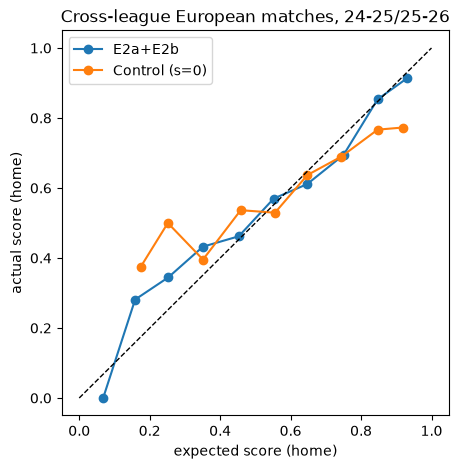

,n,expected,actual
bin,,,
"(0.0, 0.1]",4,0.068,0.000
"(0.1, 0.2]",32,0.159,0.281
"(0.2, 0.3]",74,0.253,0.345
"(0.3, 0.4]",96,0.351,0.432
"(0.4, 0.5]",145,0.453,0.462
"(0.5, 0.6]",165,0.552,0.570
"(0.6, 0.7]",171,0.647,0.611
"(0.7, 0.8]",180,0.750,0.694
"(0.8, 0.9]",126,0.847,0.853


In [20]:
mask = eu_mask(REPORT)
bins = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(5, 5))
tables = {}
for name in [WINNER, "Control (s=0)"]:
    frame = pd.DataFrame({"E": E_RUNS[name][mask], "S": S_EU[mask]})
    frame["bin"] = pd.cut(frame["E"], bins)
    table = frame.groupby("bin", observed=True).agg(n=("S", "size"), expected=("E", "mean"), actual=("S", "mean"))
    tables[name] = table
    ax.plot(table["expected"], table["actual"], "o-", label=name)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("expected score (home)")
ax.set_ylabel("actual score (home)")
ax.set_title("Cross-league European matches, 24-25/25-26")
ax.legend()
plt.show()
tables[WINNER].round(3)

**Stability of `s`** (§4A.2 validation 4): the best `s` (other parameters at
the winner's) fitted on 21-22 to 23-24, then on 24-25 to 25-26.

In [21]:
stability = []
for s in GRID["s"]:
    loss = score_loss(run({**WIN_PARAMS, "s": s}, WIN_VARIANT)["E"])
    stability.append({"s": s, "21-22 to 23-24": loss[eu_mask(["21-22", "22-23", "23-24"])].mean(),
                      "24-25 to 25-26": loss[eu_mask(REPORT)].mean()})
stability = pd.DataFrame(stability).set_index("s")
print("Best s:", {col: int(stability[col].idxmin()) for col in stability})
stability.round(4)

Best s: {'21-22 to 23-24': 150, '24-25 to 25-26': 100}


,21-22 to 23-24,24-25 to 25-26
s,,
0,0.6387,0.6322
100,0.6148,0.6193
150,0.6137,0.6211
200,0.6190,0.6282
250,0.6302,0.6401
300,0.6466,0.6567


**The league offsets** at the start of 25-26 (option A at the chosen `s`,
plus what E2b has learned by the end of 25-26), and option B: ClubElo's API.

In [22]:
final = run(WIN_PARAMS, WIN_VARIANT, final_season="25-26")
offsets = pd.DataFrame({
    "A (UEFA) 25-26": {d: uefa_offset(LEAGUE_COUNTRY[d], "25-26", WIN_PARAMS["s"]) for d in DIVS},
    "learned D_L": {d: final["learned"].get(d, 0.0) for d in DIVS},
})
offsets["O_L"] = offsets.sum(axis=1)
print(offsets.round(0))

try:
    request = urllib.request.Request("http://api.clubelo.com/2025-09-01", headers={"User-Agent": "football-analysis"})
    status = urllib.request.urlopen(request, timeout=20).status
except Exception as exc:
    status = exc
print(f"\nOption B (ClubElo) sanity check: API returned {status} - "
      f"{'run the comparison' if status == 200 else 'skipped (API down, as on 2026-11-02)'}")

     A (UEFA) 25-26  learned D_L    O_L
E0              0.0          0.0    0.0
SP1           -30.0         -5.0  -35.0
D1            -43.0          6.0  -37.0
I1            -25.0          3.0  -22.0
F1            -68.0          4.0  -64.0
P1            -92.0        -37.0 -129.0
N1            -81.0        -53.0 -134.0



Option B (ClubElo) sanity check: API returned HTTP Error 502: Bad Gateway - skipped (API down, as on 2026-11-02)


**The overall rating** (D11): every club on the shared scale at the end of
25-26. This is the object the `/ratings` page will show (P4-04).

In [23]:
final["ratings"].head(25).round(0)

,Club,League,Rating
0,Arsenal,E0,1821.0
1,Bayern München,D1,1810.0
2,Barcelona,SP1,1754.0
3,Paris Saint-Germain,F1,1740.0
4,Real Madrid,SP1,1717.0
5,Inter,I1,1716.0
6,Manchester City,E0,1705.0
7,Roma,I1,1673.0
8,FC Porto,P1,1664.0
9,Borussia Dortmund,D1,1655.0


In [24]:
# Sanity: league averages on the shared scale should sit at 1500 + O_L
final["ratings"].assign(Group=lambda f: f["League"].where(~f["League"].str.startswith("X:"), "outside the 7"))\
    .groupby("Group")["Rating"].agg(["size", "mean", "max"]).sort_values("mean", ascending=False).round(0)

,size,mean,max
Group,,,
E0,20,1532.0,1821.0
I1,20,1465.0,1716.0
D1,18,1455.0,1810.0
SP1,20,1450.0,1754.0
F1,18,1436.0,1740.0
P1,18,1338.0,1664.0
N1,18,1329.0,1573.0
outside the 7,60,1298.0,1493.0


## Conclusion

**Ships: E2a+E2b with option A offsets and no warm-up.** Parameters (chosen on
22-23/23-24): `s = 150`, `HA_CL = 80`, `K_CL = 35`, `k_L = 4`, `E_entrant = 0`,
`ρ = 0.5`.

| Gate | Result |
|---|---|
| 1. Domestic invariance (E1, E2b) | **PASS** - max \|EloDiff − pipeline\| = 4.5e-13 at every parameter set tried |
| 2. Offsets vs `s = 0` (report, 1,045 cross-league matches) | **PASS for all five** - E1 −0.0298 [−0.0435, −0.0161]; E2b −0.0363 [−0.0506, −0.0216]; E2a −0.0408 [−0.0562, −0.0253]; **E2a+E2b −0.0427 [−0.0587, −0.0263]**; C −0.0405 [−0.0547, −0.0259]; all better in 2/2 seasons |
| 3. E2a variants, domestic vs E2b (9,530 matches, 22-23 to 25-26) | **PASS** - E2a −0.0000 [−0.0009, +0.0008], Europe-club subset (5,466) −0.0000 [−0.0015, +0.0015]; E2a+E2b −0.0001 [−0.0009, +0.0008], subset −0.0001 [−0.0015, +0.0013] |
| Selection (lowest report log loss among passers) | **E2a+E2b 0.6211** < E2a 0.6229 < C 0.6233 < E2b 0.6274 < E1 0.6340 (control 0.6638); same order on tune |
| 4. Warm-up vs W0 | **Neither adopted** - W1 European −0.0000 [−0.0009, +0.0008], domestic −0.0004 [−0.0015, +0.0007]; W2 European +0.0002 [−0.0006, +0.0010], domestic −0.0007 [−0.0021, +0.0007] |

**What it means**

- **League strength is real and large.** Putting leagues on one scale cuts
  European cross-league log loss by about 0.04 - roughly ten times the size of
  a typical domestic model improvement. The gain is biggest between two
  modelled leagues (−0.068 for E2a+E2b) but holds against outsiders too.
- **Let European results move the ratings.** Learning at league level (E2b)
  beats static offsets by −0.0065 [−0.0101, −0.0028]; adding team-level
  transfers beats E2b by a further −0.0063 [−0.0113, −0.0013]. E2a+E2b vs E2a
  alone is −0.0018 [−0.0038, +0.0003]: a small, not quite significant edge.
- **Domestic predictions don't care.** E2a's changes to the `EloDiff` of
  clubs in Europe leave domestic log loss unchanged to four decimals - so the
  team-level updates cost nothing domestically and make the shared rating
  (D11's overall ranking) individual: Arsenal and Bayern lead it, not just
  their leagues.
- **UEFA's coefficient overrates Portugal and the Netherlands on our scale.**
  Both learned corrections agree: E2b ends 25-26 with P1 −37 and N1 −53 below
  option A, and option C's free fit puts them at −150 to −176 against A's
  −80 to −104. The other leagues' corrections are within ±6.
- **Option C** (offsets fitted directly) beats static A (−0.0107
  [−0.0153, −0.0061]) but is static; E2a+E2b gets the same information online
  and does slightly better, without a yearly refit.
- **Robustness.** `s` is stable (best 150 on 21-22 to 23-24, 100 on 24-25 to
  25-26). Values chosen past the grid's edges improve tune loss but not report
  loss (E1 significantly worse), so the planned grid's values stand.
  Reliability shows cross-league gaps slightly too wide (home underdogs at
  E ≈ 0.25 score 0.35; favourites at 0.75 score 0.69); Phase 5's LR uses
  `EloDiff` as a feature and recalibrates this.
- **Option B (ClubElo)** couldn't run: the API returned 502 again.

**For P4-04 and the owner**

- Under E2a, domestic ratings depend on European results, so the daily run
  must ingest **CL, EL and ECL** results before rating domestic fixtures (about
  20-30 FotMob calls on a European matchday). E2b alone keeps domestic
  `EloDiff` invariant and needs European results only for the shared scale,
  at a cost of 0.0063 European log loss. The gate rule picks E2a+E2b.
- Re-centring removes promotion drift but keeps European transfers, so a
  league's average drifts with its European record (E0 averages 1532 at the end
  of 25-26).
